# P-RSoXR JAX Speed Benchmark

This notebook compares the speed of the **CPU (numpy) 4×4 TMM** implementation against the
**JAX-accelerated** implementation introduced in the compatibility update.

Tests use the same models and bundled example data as the official PyPXR tutorials:
- **Tutorial 1**: Single-energy reflectivity (posaconazole on Si, 284.7 eV)
- **Tutorial 2**: Multi-energy simultaneous refinement (2 energies: 284.7 and 285.7 eV)

## Sections
1. [Setup](#1.-Setup)
2. [Build models from Tutorial 1 & 2](#2.-Build-models)
3. [Single-call speed: numpy vs JAX float64 vs JAX float32](#3.-Single-call-speed)
4. [Batch speed: simulating one CMA-ES generation](#4.-Batch-speed)
5. [Multi-energy batch (PXRBatchBuilder)](#5.-Multi-energy-batch)
6. [Full optimizer: pxr_gpu_fit_models_cmaes](#6.-Full-optimizer)

## 1. Setup

In [1]:
%matplotlib inline
import os, sys, time
import numpy as np
import matplotlib.pyplot as plt

# --- PyPXR (installed in this environment) ---
from pypxr.reflectivity import PXR_reflectivity, PXR_ReflectModel, _JAX_AVAILABLE
from pypxr.structure import PXR_Structure, PXR_Slab, PXR_SLD, PXR_MaterialSLD
from pypxr._uniaxial_reflect import uniaxial_reflectivity

# --- refnx for fitting objectives ---
from refnx.dataset import ReflectDataset
from refnx.analysis import Transform, Objective, GlobalObjective

print(f"JAX available: {_JAX_AVAILABLE}")

if _JAX_AVAILABLE:
    import jax
    import jax.numpy as jnp
    from pypxr._jax_uniaxial_reflect import (
        uniaxial_reflectivity_jax,
        uniaxial_reflectivity_jax_f32,
    )
    from pypxr._jax_pxr_batch import PXRBatchBuilder, pxr_gpu_fit_models_cmaes
    print(f"JAX version : {jax.__version__}")
    devices = jax.devices()
    print(f"JAX devices : {devices}")

JAX available: True
JAX version : 0.10.0
JAX devices : [CudaDevice(id=0), CudaDevice(id=1), CudaDevice(id=2)]


In [2]:
# --- Locate bundled example data ---
import pypxr as _pypxr
_pkg_dir = os.path.dirname(_pypxr.__file__)
EXAMPLE_DATA = os.path.join(_pkg_dir, 'example_data')
print(f"Example data directory: {EXAMPLE_DATA}")
print("Files:", sorted(os.listdir(EXAMPLE_DATA)))

Example data directory: /homes/dfs1/P-RSoXR/src/pypxr/example_data
Files: ['Example_Run_Script.txt', 'Feb19_Exp101_p100.txt', 'Feb19_Exp101_p190.txt', 'Feb19_Exp102_p100.txt', 'Feb19_Exp102_p190.txt', 'MF201']


## 2. Build models

Reproduce the structures from Tutorial 1 (single energy) and Tutorial 2 (multi-energy).
These use the bundled `Feb19_Exp10x_p1y0.txt` datasets.

In [3]:
# ── Load example data ───────────────────────────────────────────────────────
en1, en2 = 284.7, 285.7  # eV

data_s1 = np.genfromtxt(os.path.join(EXAMPLE_DATA, 'Feb19_Exp101_p100.txt'), delimiter='\t')
data_p1 = np.genfromtxt(os.path.join(EXAMPLE_DATA, 'Feb19_Exp101_p190.txt'), delimiter='\t')
data_s2 = np.genfromtxt(os.path.join(EXAMPLE_DATA, 'Feb19_Exp102_p100.txt'), delimiter='\t')
data_p2 = np.genfromtxt(os.path.join(EXAMPLE_DATA, 'Feb19_Exp102_p190.txt'), delimiter='\t')

print(f"en1 s-pol: {data_s1.shape[0]} points  q=[{data_s1[:,0].min():.4f}, {data_s1[:,0].max():.4f}] Å⁻¹")
print(f"en1 p-pol: {data_p1.shape[0]} points")
print(f"en2 s-pol: {data_s2.shape[0]} points  q=[{data_s2[:,0].min():.4f}, {data_s2[:,0].max():.4f}] Å⁻¹")
print(f"en2 p-pol: {data_p2.shape[0]} points")

en1 s-pol: 305 points  q=[0.0057, 0.2500] Å⁻¹
en1 p-pol: 305 points
en2 s-pol: 291 points  q=[0.0129, 0.2510] Å⁻¹
en2 p-pol: 288 points


In [4]:
# ── Non-resonant substrate / superstrate (shared between energies) ───────────
si    = PXR_MaterialSLD('Si',   density=2.33, name='Si')
sio2  = PXR_MaterialSLD('SiO2', density=2.28, name='SiO2')
vacuum = PXR_MaterialSLD('',    density=1,    name='vacuum')

si_slab   = si(0, 0.5)
sio2_slab = sio2(12, 1)

# ── Energy 1 (284.7 eV): resonant layers ─────────────────────────────────────
posa_en1         = PXR_SLD(np.array([complex(-0.00043, 0.0001),  complex(-0.00049, 0.00019)]),  name='posa1')
posa_surf_en1    = PXR_SLD(np.array([complex(-0.00019, 0.00152), complex(-0.00020, 0.00001)]),  name='posa1_surf')
posa_slab_en1      = posa_en1(711, 1)
posa_surf_slab_en1 = posa_surf_en1(20, 1)

# ── Energy 2 (285.7 eV): resonant layers ─────────────────────────────────────
posa_en2         = PXR_SLD(np.array([complex(0.00097, 0.0007),    complex(0.00120, 0.0007)]),   name='posa2')
posa_surf_en2    = PXR_SLD(np.array([complex(0.00146579, 0.00001), complex(0.00061, 0.00050)]),  name='posa2_surf')
posa_slab_en2      = posa_en2(711, 1)
posa_surf_slab_en2 = posa_surf_en2(20, 1)

# ── Structures ────────────────────────────────────────────────────────────────
structure_en1 = vacuum | posa_surf_slab_en1 | posa_slab_en1 | sio2_slab | si_slab
structure_en2 = vacuum | posa_surf_slab_en2 | posa_slab_en2 | sio2_slab | si_slab

print("Structures built. Layer counts:")
print(f"  en1: {structure_en1.slabs().shape[0]} slabs, tensor shape {structure_en1.tensor(energy=en1).shape}")
print(f"  en2: {structure_en2.slabs().shape[0]} slabs, tensor shape {structure_en2.tensor(energy=en2).shape}")

Structures built. Layer counts:
  en1: 5 slabs, tensor shape (5, 3, 3)
  en2: 5 slabs, tensor shape (5, 3, 3)


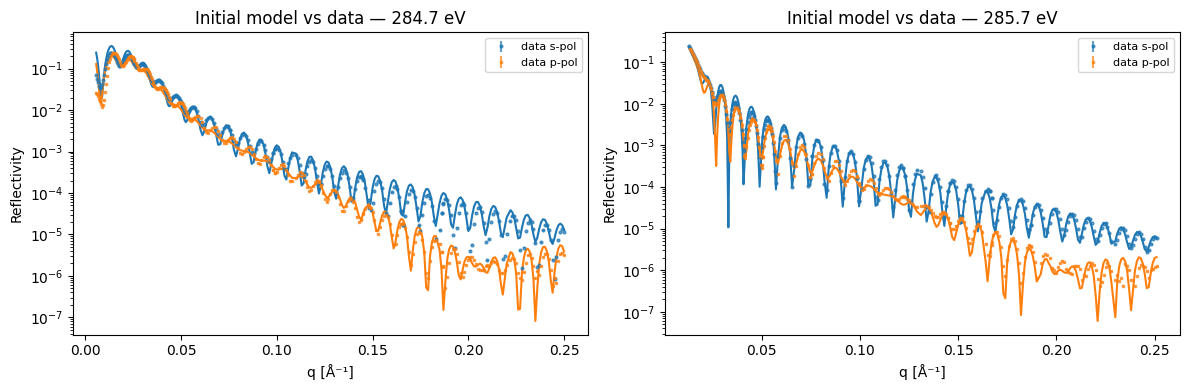

In [5]:
# ── PXR_ReflectModel objects — one per polarization per energy ────────────────
# Note: PXRBatchBuilder requires single-polarization objectives (pol='s' or pol='p').
# For simultaneous s+p fitting, pass both as separate objectives.
model_s_en1 = PXR_ReflectModel(structure_en1, energy=en1, pol='s', name='s_en1')
model_p_en1 = PXR_ReflectModel(structure_en1, energy=en1, pol='p', name='p_en1')
model_s_en2 = PXR_ReflectModel(structure_en2, energy=en2, pol='s', name='s_en2')
model_p_en2 = PXR_ReflectModel(structure_en2, energy=en2, pol='p', name='p_en2')

# ── refnx Objective objects ───────────────────────────────────────────────────
from refnx.dataset import ReflectDataset
ds_s1 = ReflectDataset(data_s1.T)
ds_p1 = ReflectDataset(data_p1.T)
ds_s2 = ReflectDataset(data_s2.T)
ds_p2 = ReflectDataset(data_p2.T)

obj_s_en1 = Objective(model_s_en1, ds_s1, transform=Transform('logY'))
obj_p_en1 = Objective(model_p_en1, ds_p1, transform=Transform('logY'))
obj_s_en2 = Objective(model_s_en2, ds_s2, transform=Transform('logY'))
obj_p_en2 = Objective(model_p_en2, ds_p2, transform=Transform('logY'))

# Also make combined sp model for plotting convenience (not used in batch optimizer)
model_en1 = PXR_ReflectModel(structure_en1, energy=en1, pol='sp')
model_en2 = PXR_ReflectModel(structure_en2, energy=en2, pol='sp')
data_concat_en1 = ReflectDataset(np.concatenate([data_s1, data_p1]).T)
data_concat_en2 = ReflectDataset(np.concatenate([data_s2, data_p2]).T)
obj_en1 = Objective(model_en1, data_concat_en1, transform=Transform('logY'))
obj_en2 = Objective(model_en2, data_concat_en2, transform=Transform('logY'))

# Quick initial plot to confirm the model is reasonable
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (obj_s, obj_p), (dat_s, dat_p), en in zip(
    axes,
    [(obj_s_en1, obj_p_en1), (obj_s_en2, obj_p_en2)],
    [(data_s1,  data_p1),    (data_s2,  data_p2)],
    [en1, en2]
):
    ax.errorbar(dat_s[:, 0], dat_s[:, 1], dat_s[:, 2],
                fmt='o', ms=2, color='C0', label='data s-pol', alpha=0.7)
    ax.errorbar(dat_p[:, 0], dat_p[:, 1], dat_p[:, 2],
                fmt='s', ms=2, color='C1', label='data p-pol', alpha=0.7)
    ax.semilogy(dat_s[:, 0], obj_s.model(dat_s[:, 0]), 'C0-', lw=1.5)
    ax.semilogy(dat_p[:, 0], obj_p.model(dat_p[:, 0]), 'C1-', lw=1.5)
    ax.set_title(f'Initial model vs data — {en} eV')
    ax.set_yscale('log')
    ax.set_xlabel('q [Å⁻¹]')
    ax.set_ylabel('Reflectivity')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3. Single-call speed: numpy vs JAX

Time the core reflectivity calculation for a single set of parameters.
This simulates the cost of evaluating one candidate in the optimizer.

In [6]:
# Extract raw arrays for the low-level timing tests
slabs1  = structure_en1.slabs()[:, :4]            # (nlayers, 4)
tensor1 = structure_en1.tensor(energy=en1)         # (nlayers, 3, 3) complex
q1      = data_s1[:, 0]                            # q values for en1 s-pol

print(f"Slabs  shape: {slabs1.shape}")
print(f"Tensor shape: {tensor1.shape}")
print(f"Q      shape: {q1.shape}")
print(f"q range: [{q1.min():.4f}, {q1.max():.4f}] Å⁻¹")

Slabs  shape: (5, 4)
Tensor shape: (5, 3, 3)
Q      shape: (305,)
q range: [0.0057, 0.2500] Å⁻¹


float64 JAX vs numpy   max |Δ| = 6.08e-14  (should be < 1e-10)
float32 JAX vs numpy   max |Δ| = 1.31e-04


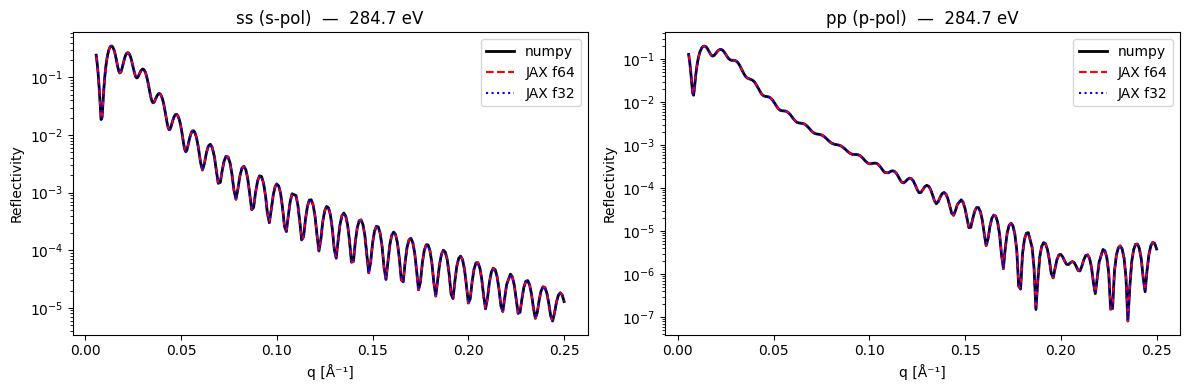

In [7]:
# ── Verify numerical equivalence before benchmarking ─────────────────────────
if _JAX_AVAILABLE:
    refl_np,  *_ = uniaxial_reflectivity(q1, slabs1, tensor1, en1)
    refl_jax, _  = uniaxial_reflectivity_jax(
        jnp.array(q1), jnp.array(slabs1), jnp.array(tensor1), en1
    )
    refl_jax = np.array(refl_jax)
    refl_f32 = np.array(uniaxial_reflectivity_jax_f32(
        jnp.array(q1), jnp.array(slabs1), jnp.array(tensor1), en1
    ))

    err64 = np.max(np.abs(refl_jax - refl_np))
    err32 = np.max(np.abs(refl_f32 - refl_np))
    print(f"float64 JAX vs numpy   max |Δ| = {err64:.2e}  (should be < 1e-10)")
    print(f"float32 JAX vs numpy   max |Δ| = {err32:.2e}")

    # Plot both polarizations from numpy and JAX to confirm they match
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
    for ax, (i, j), label in zip(axes, [(1,1),(0,0)], ['ss (s-pol)', 'pp (p-pol)']):
        ax.semilogy(q1, refl_np[:,i,j],   'k-',  lw=2,   label='numpy')
        ax.semilogy(q1, refl_jax[:,i,j],  'r--', lw=1.5, label='JAX f64')
        ax.semilogy(q1, refl_f32[:,i,j],  'b:',  lw=1.5, label='JAX f32')
        ax.set_title(f'{label}  —  {en1} eV')
        ax.set_xlabel('q [Å⁻¹]')
        ax.set_ylabel('Reflectivity')
        ax.legend()
    plt.tight_layout()
    plt.show()

In [8]:
# ── Warm up JAX JIT compilation (first call compiles, subsequent calls are fast) ──
if _JAX_AVAILABLE:
    print("Warming up JAX JIT...")
    for _ in range(3):
        _ = uniaxial_reflectivity_jax(
            jnp.array(q1), jnp.array(slabs1), jnp.array(tensor1), en1
        )
        _ = uniaxial_reflectivity_jax_f32(
            jnp.array(q1), jnp.array(slabs1), jnp.array(tensor1), en1
        )
    jax.block_until_ready(_)
    print("Warm-up complete.")

Warming up JAX JIT...
Warm-up complete.


In [9]:
N_REPEAT = 200  # repetitions for timing

# ── (A) numpy 4×4 TMM ─────────────────────────────────────────────────────────
t0 = time.perf_counter()
for _ in range(N_REPEAT):
    uniaxial_reflectivity(q1, slabs1, tensor1, en1)
t_numpy = (time.perf_counter() - t0) / N_REPEAT * 1e3
print(f"numpy 4×4 TMM (float64)    : {t_numpy:.3f} ms/call")

if _JAX_AVAILABLE:
    q1j = jnp.array(q1)
    s1j = jnp.array(slabs1)
    t1j = jnp.array(tensor1)

    # ── (B) JAX float64 ──────────────────────────────────────────────────────
    t0 = time.perf_counter()
    for _ in range(N_REPEAT):
        r = uniaxial_reflectivity_jax(q1j, s1j, t1j, en1)
    jax.block_until_ready(r)
    t_jax64 = (time.perf_counter() - t0) / N_REPEAT * 1e3
    print(f"JAX 4×4 TMM  (float64)     : {t_jax64:.3f} ms/call  →  {t_numpy/t_jax64:.1f}× speedup")

    # ── (C) JAX float32 ──────────────────────────────────────────────────────
    t0 = time.perf_counter()
    for _ in range(N_REPEAT):
        r = uniaxial_reflectivity_jax_f32(q1j, s1j, t1j, en1)
    jax.block_until_ready(r)
    t_jax32 = (time.perf_counter() - t0) / N_REPEAT * 1e3
    print(f"JAX 4×4 TMM  (float32)     : {t_jax32:.3f} ms/call  →  {t_numpy/t_jax32:.1f}× speedup")

    # ── (D) High-level backend='jax' via PXR_reflectivity ────────────────────
    t0 = time.perf_counter()
    for _ in range(N_REPEAT):
        PXR_reflectivity(q1, slabs1, tensor1, en1, backend='jax')
    jax.block_until_ready(r)  # just ensures GPU is finished
    t_dispatch = (time.perf_counter() - t0) / N_REPEAT * 1e3
    print(f"PXR_reflectivity backend=jax : {t_dispatch:.3f} ms/call  (includes Python overhead)")

numpy 4×4 TMM (float64)    : 8.474 ms/call
JAX 4×4 TMM  (float64)     : 0.527 ms/call  →  16.1× speedup
JAX 4×4 TMM  (float32)     : 0.339 ms/call  →  25.0× speedup
PXR_reflectivity backend=jax : 1.721 ms/call  (includes Python overhead)


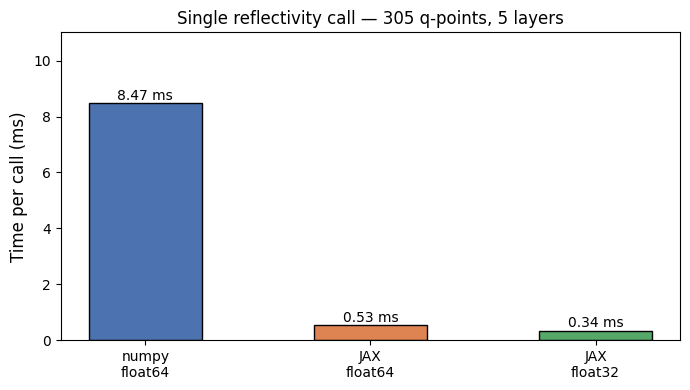

In [10]:
if _JAX_AVAILABLE:
    labels  = ['numpy\nfloat64', 'JAX\nfloat64', 'JAX\nfloat32']
    times   = [t_numpy, t_jax64, t_jax32]
    colors  = ['#4C72B0', '#DD8452', '#55A868']

    fig, ax = plt.subplots(figsize=(7, 4))
    bars = ax.bar(labels, times, color=colors, edgecolor='k', width=0.5)
    for bar, t in zip(bars, times):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                f'{t:.2f} ms', ha='center', va='bottom', fontsize=10)
    ax.set_ylabel('Time per call (ms)', fontsize=12)
    ax.set_title(f'Single reflectivity call — {q1.shape[0]} q-points, {slabs1.shape[0]} layers',
                 fontsize=12)
    ax.set_ylim(0, max(times) * 1.3)
    plt.tight_layout()
    plt.show()

## 4. Batch speed: simulating one CMA-ES generation

The optimizer evaluates `popsize` candidate parameter sets per generation.
Here we benchmark how long it takes to evaluate the reflectivity and chi² for
an entire population at a single energy.

In [11]:
# ── Set up free parameters ────────────────────────────────────────────────────
# Note: each energy is treated as INDEPENDENT by PXRBatchBuilder (per-energy
# CMA-ES populations, no cross-energy hard constraints). The joint chi2
# minimisation naturally encourages convergence to physically consistent
# structural parameters across energies.
si_slab.thick.setp(vary=False)
si_slab.rough.setp(vary=False, bounds=(1, 2))
sio2_slab.thick.setp(vary=False, bounds=(5, 20))
sio2_slab.rough.setp(vary=True, bounds=(1, 10))
sio2_slab.sld.density.setp(vary=False)

posa_slab_en1.thick.setp(vary=True, bounds=(400, 900))
posa_slab_en1.rough.setp(vary=True, bounds=(0.2, 20))
posa_slab_en1.sld.xx.setp(vary=True,  bounds=(-0.01, -1e-7))
posa_slab_en1.sld.zz.setp(vary=True,  bounds=(-0.01, -1e-7))
posa_slab_en1.sld.ixx.setp(vary=True, bounds=(0, 0.01))
posa_slab_en1.sld.izz.setp(vary=True, bounds=(0, 0.01))

posa_surf_slab_en1.thick.setp(vary=True, bounds=(5, 30))
posa_surf_slab_en1.rough.setp(vary=True, bounds=(0.5, 20))
posa_surf_slab_en1.sld.xx.setp(vary=True,  bounds=(-0.1, -1e-7))
posa_surf_slab_en1.sld.zz.setp(vary=True,  bounds=(-0.1, -1e-7))
posa_surf_slab_en1.sld.ixx.setp(vary=True, bounds=(0, 0.01))
posa_surf_slab_en1.sld.izz.setp(vary=True, bounds=(0, 0.01))

# En2: independent parameters (same bounds as en1 for geometry)
posa_slab_en2.thick.setp(vary=True, bounds=(400, 900))
posa_slab_en2.rough.setp(vary=True, bounds=(0.2, 20))
posa_slab_en2.sld.xx.setp(vary=True,  bounds=(-0.01, 0.01))
posa_slab_en2.sld.zz.setp(vary=True,  bounds=(-0.01, 0.01))
posa_slab_en2.sld.ixx.setp(vary=True, bounds=(0, 0.01))
posa_slab_en2.sld.izz.setp(vary=True, bounds=(0, 0.01))

posa_surf_slab_en2.thick.setp(vary=True, bounds=(5, 30))
posa_surf_slab_en2.rough.setp(vary=True, bounds=(0.5, 20))
posa_surf_slab_en2.sld.xx.setp(vary=True,  bounds=(-0.01, 0.01))
posa_surf_slab_en2.sld.zz.setp(vary=True,  bounds=(-0.01, 0.01))
posa_surf_slab_en2.sld.ixx.setp(vary=True, bounds=(0, 0.01))
posa_surf_slab_en2.sld.izz.setp(vary=True, bounds=(0, 0.01))

from pypxr._jax_pxr_batch import _extract_free_params
free1 = _extract_free_params(obj_s_en1)
free2 = _extract_free_params(obj_s_en2)
print(f"Free parameters — en1: {len(free1)}, en2: {len(free2)}")
for p in free1:
    print(f"  {p.name:30s}  value={p.value:.6g}  bounds=[{p.bounds.lb:.4g}, {p.bounds.ub:.4g}]")


Free parameters — en1: 13, en2: 13
  posa1_surf_thick                value=20  bounds=[5, 30]
  posa1_surf_xx                   value=-0.00019  bounds=[-0.1, -1e-07]
  posa1_surf_ixx                  value=0.00152  bounds=[0, 0.01]
  posa1_surf_zz                   value=-0.0002  bounds=[-0.1, -1e-07]
  posa1_surf_izz                  value=1e-05  bounds=[0, 0.01]
  posa1_surf_rough                value=1  bounds=[0.5, 20]
  posa1_thick                     value=711  bounds=[400, 900]
  posa1_xx                        value=-0.00043  bounds=[-0.01, -1e-07]
  posa1_ixx                       value=0.0001  bounds=[0, 0.01]
  posa1_zz                        value=-0.00049  bounds=[-0.01, -1e-07]
  posa1_izz                       value=0.00019  bounds=[0, 0.01]
  posa1_rough                     value=1  bounds=[0.2, 20]
  SiO2_rough                      value=1  bounds=[1, 10]


In [12]:
if not _JAX_AVAILABLE:
    print("JAX not available — skipping batch benchmark.")
else:
    from pypxr._jax_pxr_batch import PXRBatchBuilder, _extract_free_params, _get_bounds

    POPSIZE_LIST = [5, 10, 20, 50, 100]
    N_TIME = 5  # repetitions

    # Build single-energy batch builder (en1 only)
    objectives_single = {en1: obj_s_en1}  # s-pol only
    builder_single = PXRBatchBuilder(objectives_single)

    results_numpy = []   # CPU loop
    results_jax   = []   # JAX batch

    print(f"Benchmarking single-energy batch ({slabs1.shape[0]} layers, {data_s1.shape[0]} q-points)...")
    print(f"  {'popsize':>8}  {'numpy loop (ms)':>18}  {'JAX batch (ms)':>18}  {'speedup':>10}")

    for popsize in POPSIZE_LIST:
        # Random population within bounds
        bounds = _get_bounds(_extract_free_params(obj_s_en1))
        rng = np.random.default_rng(42)
        pop = rng.uniform(bounds[:, 0], bounds[:, 1], (1, popsize, builder_single.n_free))

        # ── Numpy: evaluate model per candidate in a Python loop ──────────────
        import copy as _copy
        from pypxr._jax_pxr_batch import _set_free_params, _get_pxr_state

        t0 = time.perf_counter()
        for _ in range(N_TIME):
            chi2_loop = []
            for cand in pop[0]:
                _set_free_params(obj_s_en1, cand)
                r, *_ = PXR_reflectivity(
                    data_s1[:, 0],
                    structure_en1.slabs()[:, :4],
                    structure_en1.tensor(energy=en1),
                    en1,
                )
        t_np = (time.perf_counter() - t0) / N_TIME * 1e3
        # Restore base params
        _set_free_params(obj_s_en1, np.array([p.value for p in builder_single.free_params]))

        # ── JAX: PXRBatchBuilder.fitness() ────────────────────────────────────
        # First call includes any remaining JIT compilation
        _ = builder_single.fitness(pop)
        t0 = time.perf_counter()
        for _ in range(N_TIME):
            chi2_jax = builder_single.fitness(pop)
        t_jax = (time.perf_counter() - t0) / N_TIME * 1e3

        results_numpy.append(t_np)
        results_jax.append(t_jax)
        print(f"  {popsize:>8}  {t_np:>18.2f}  {t_jax:>18.2f}  {t_np/t_jax:>10.2f}×")

Benchmarking single-energy batch (5 layers, 305 q-points)...
   popsize     numpy loop (ms)      JAX batch (ms)     speedup
         5               44.60                4.49        9.94×
        10               89.13                6.90       12.91×
        20              178.61               11.84       15.08×
        50              444.78               27.94       15.92×
       100              891.35               56.17       15.87×


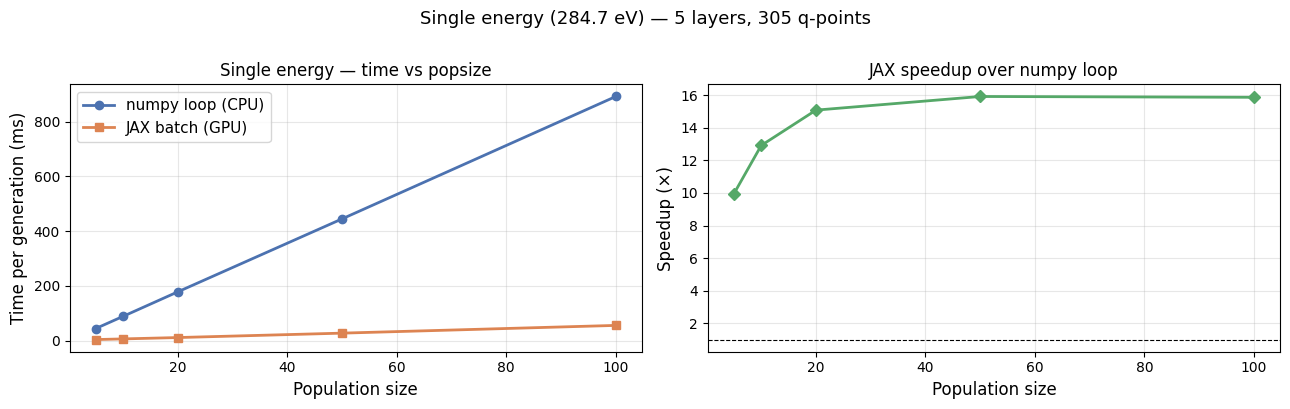

In [13]:
if _JAX_AVAILABLE:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    ax = axes[0]
    ax.plot(POPSIZE_LIST, results_numpy, 'o-', color='#4C72B0', lw=2, label='numpy loop (CPU)')
    ax.plot(POPSIZE_LIST, results_jax,   's-', color='#DD8452', lw=2, label='JAX batch (GPU)')
    ax.set_xlabel('Population size', fontsize=12)
    ax.set_ylabel('Time per generation (ms)', fontsize=12)
    ax.set_title('Single energy — time vs popsize', fontsize=12)
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3)

    ax = axes[1]
    speedups = [n/j for n, j in zip(results_numpy, results_jax)]
    ax.plot(POPSIZE_LIST, speedups, 'D-', color='#55A868', lw=2)
    ax.axhline(1, color='k', lw=0.8, ls='--')
    ax.set_xlabel('Population size', fontsize=12)
    ax.set_ylabel('Speedup (×)', fontsize=12)
    ax.set_title('JAX speedup over numpy loop', fontsize=12)
    ax.grid(True, alpha=0.3)

    plt.suptitle(f'Single energy ({en1} eV) — {slabs1.shape[0]} layers, {data_s1.shape[0]} q-points',
                 fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()

## 5. Multi-energy batch (PXRBatchBuilder)

Build the `PXRBatchBuilder` with both energies (284.7 and 285.7 eV) and
compare the cost of evaluating a full population across both energies simultaneously.

In [14]:
if _JAX_AVAILABLE:
    # Pass all 4 objectives (s+p for each energy) as a list
    # PXRBatchBuilder reads energy from obj.model.energy
    objectives_multi = [obj_s_en1, obj_p_en1, obj_s_en2, obj_p_en2]
    builder_multi = PXRBatchBuilder(objectives_multi)

    print("PXRBatchBuilder — multi-energy summary:")
    print(f"  Energies      : {builder_multi.energies}")
    print(f"  n_energies    : {builder_multi.n_energies}  (2 energies × 2 polarizations)")
    print(f"  n_free        : {builder_multi.n_free}")
    print(f"  n_slab_rows   : {builder_multi.n_slab_rows}")
    print(f"  max_nq        : {builder_multi.max_nq}  (padded q-array)")
    print(f"  use_log       : {builder_multi.use_log}")

PXRBatchBuilder — multi-energy summary:
  Energies      : [284.7, 284.7, 285.7, 285.7]
  n_energies    : 4  (2 energies × 2 polarizations)
  n_free        : 13
  n_slab_rows   : 5
  max_nq        : 305  (padded q-array)
  use_log       : True


In [15]:
if _JAX_AVAILABLE:
    N_EN   = builder_multi.n_energies  # 4 (2 energies × 2 pol)
    N_FREE = builder_multi.n_free
    bounds_multi = builder_multi.per_energy_bounds  # (n_e, n_free, 2)
    N_TIME = 5  # repetitions

    POPSIZE_LIST_MULTI = [5, 10, 20, 50, 100]
    results_numpy_multi = []
    results_jax_multi   = []

    print(f"Benchmarking multi-pol/energy batch ({N_EN} conditions, {N_FREE} free params)...")
    print(f"  {'popsize':>8}  {'numpy loop (ms)':>18}  {'JAX batch (ms)':>18}  {'speedup':>10}")

    for popsize in POPSIZE_LIST_MULTI:
        rng = np.random.default_rng(42)
        pop = np.stack([
            rng.uniform(bounds_multi[i, :, 0], bounds_multi[i, :, 1], (popsize, N_FREE))
            for i in range(N_EN)
        ])  # (n_e, popsize, n_free)

        # ── Numpy: sequential loop over conditions × candidates ────────────────
        t0 = time.perf_counter()
        for _ in range(N_TIME):
            for i, (obj, en) in enumerate(zip(builder_multi.objectives, builder_multi.energies)):
                fp = _extract_free_params(obj)
                saved = np.array([p.value for p in fp])
                for j in range(popsize):
                    _set_free_params(obj, pop[i, j])
                    PXR_reflectivity(
                        builder_multi.q_list[i],
                        obj.model.structure.slabs()[:, :4],
                        obj.model.structure.tensor(energy=en),
                        en
                    )
                _set_free_params(obj, saved)
        t_np_multi = (time.perf_counter() - t0) / N_TIME * 1e3

        # ── JAX: PXRBatchBuilder.fitness() ─────────────────────────────────────
        _ = builder_multi.fitness(pop)  # ensure JIT compiled
        t0 = time.perf_counter()
        for _ in range(N_TIME):
            chi2_jax_multi = builder_multi.fitness(pop)
        t_jax_multi = (time.perf_counter() - t0) / N_TIME * 1e3

        results_numpy_multi.append(t_np_multi)
        results_jax_multi.append(t_jax_multi)
        print(f"  {popsize:>8}  {t_np_multi:>18.2f}  {t_jax_multi:>18.2f}  {t_np_multi/t_jax_multi:>10.2f}×")

Benchmarking multi-pol/energy batch (4 conditions, 13 free params)...
   popsize     numpy loop (ms)      JAX batch (ms)     speedup
         5              173.07               12.00       14.43×
        10              330.99               22.34       14.82×
        20              681.62               45.26       15.06×
        50             1714.17              111.43       15.38×
       100             3369.60              352.76        9.55×


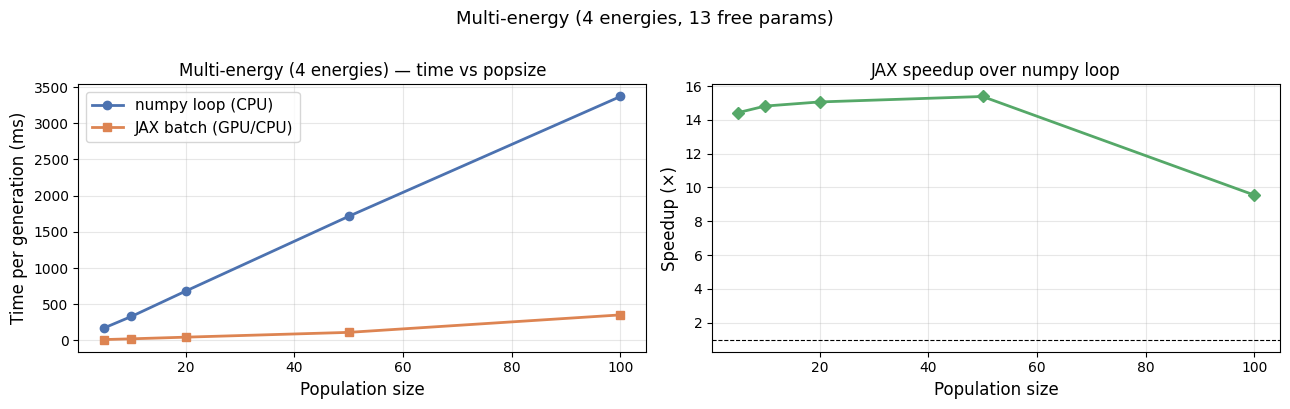

In [16]:
if _JAX_AVAILABLE:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    ax = axes[0]
    ax.plot(POPSIZE_LIST_MULTI, results_numpy_multi, 'o-', color='#4C72B0', lw=2, label='numpy loop (CPU)')
    ax.plot(POPSIZE_LIST_MULTI, results_jax_multi,   's-', color='#DD8452', lw=2, label='JAX batch (GPU/CPU)')
    ax.set_xlabel('Population size', fontsize=12)
    ax.set_ylabel('Time per generation (ms)', fontsize=12)
    ax.set_title(f'Multi-energy ({N_EN} energies) — time vs popsize', fontsize=12)
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3)

    ax = axes[1]
    speedups_multi = [n/j for n, j in zip(results_numpy_multi, results_jax_multi)]
    ax.plot(POPSIZE_LIST_MULTI, speedups_multi, 'D-', color='#55A868', lw=2)
    ax.axhline(1, color='k', lw=0.8, ls='--')
    ax.set_xlabel('Population size', fontsize=12)
    ax.set_ylabel('Speedup (×)', fontsize=12)
    ax.set_title('JAX speedup over numpy loop', fontsize=12)
    ax.grid(True, alpha=0.3)

    plt.suptitle(f'Multi-energy ({N_EN} energies, {N_FREE} free params)',
                 fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()

## 6. Full optimizer: pxr_gpu_fit_models_cmaes

Run a short CMA-ES optimization (50 generations) on the two-energy problem
and compare the wall time against what the emcee MCMC sampler achieves in the
same wall time.

The CMA-ES optimizer is expected to find a **good initial solution quickly**
which can then seed an MCMC chain for uncertainty quantification.

In [23]:
if not _JAX_AVAILABLE:
    print("JAX not available — skipping CMA-ES benchmark.")
else:
    print("Running pxr_gpu_fit_models_cmaes (100 generations, popsize=20)...")
    print("  NOTE: First call includes XLA JIT compilation (~5–15 s on first run in session)")

    t_start = time.perf_counter()
    result = pxr_gpu_fit_models_cmaes(
        [obj_s_en1, obj_p_en1, obj_s_en2, obj_p_en2],
        popsize=40,
        n_generations=10000,
        seed=42,
        verbose=True,
        tol=1e-4,
        patience=5,
        check_every=10,
    )
    t_total = time.perf_counter() - t_start

    print(f"\nFitting complete in {result['elapsed_sec']:.1f} s  "
          f"(total wall time incl. compilation: {t_total:.1f} s)")
    print(f"  Generations run : {result['generations_run']}")
    print(f"  Converged       : {result['converged']}")
    for en, chi2 in result['best_chisqr'].items():
        print(f"  χ² at {en} eV   : {chi2:.4f}")

Running pxr_gpu_fit_models_cmaes (100 generations, popsize=20)...
  NOTE: First call includes XLA JIT compilation (~5–15 s on first run in session)
  Warming up JIT compilation...
  Warmup done.
  gen   11/10000  mean_χ²=2740708.181  min_χ²=950979.923  max_χ²=4781625.612
  gen   21/10000  mean_χ²=2389498.962  min_χ²=950979.923  max_χ²=4087144.082
  gen   31/10000  mean_χ²=2076673.365  min_χ²=950979.923  max_χ²=3733577.675
  gen   41/10000  mean_χ²=1739124.762  min_χ²=950979.923  max_χ²=3493161.513
  gen   51/10000  mean_χ²=1641723.659  min_χ²=950979.923  max_χ²=3493161.513
  gen   61/10000  mean_χ²=1609035.887  min_χ²=898930.181  max_χ²=3493161.513
  gen   71/10000  mean_χ²=1603679.822  min_χ²=877505.918  max_χ²=3493161.513
  gen   81/10000  mean_χ²=1601540.623  min_χ²=868949.123  max_χ²=3493161.513
  gen   91/10000  mean_χ²=1596427.874  min_χ²=867475.506  max_χ²=3493161.513
  gen  101/10000  mean_χ²=1592558.346  min_χ²=866956.131  max_χ²=3493161.513
  gen  111/10000  mean_χ²=1581919.1

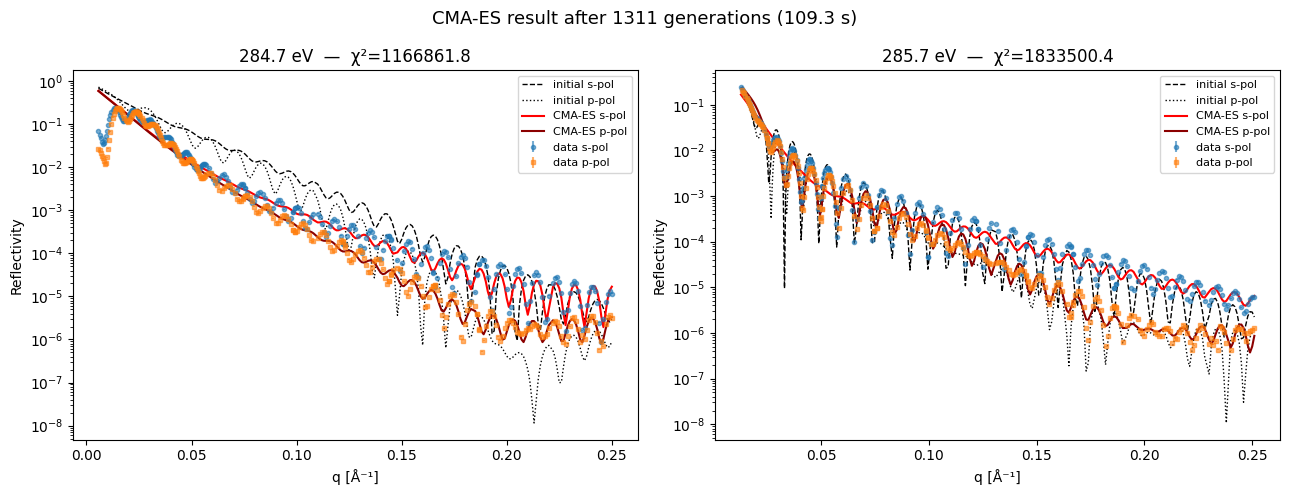

In [24]:
if _JAX_AVAILABLE and 'result' in dir():
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    fitted_objs = result['fitted_objectives']

    for ax, (en, obj_s_orig, obj_p_orig, dat_s, dat_p) in zip(
        axes,
        [(en1, obj_s_en1, obj_p_en1, data_s1, data_p1),
         (en2, obj_s_en2, obj_p_en2, data_s2, data_p2)]
    ):
        # Data
        ax.errorbar(dat_s[:, 0], dat_s[:, 1], dat_s[:, 2],
                    fmt='o', ms=3, color='C0', label='data s-pol', alpha=0.6)
        ax.errorbar(dat_p[:, 0], dat_p[:, 1], dat_p[:, 2],
                    fmt='s', ms=3, color='C1', label='data p-pol', alpha=0.6)

        # Before fit
        q_s = dat_s[:, 0]
        q_p = dat_p[:, 0]
        ax.semilogy(q_s, obj_s_orig.model(q_s), 'k--', lw=1, label='initial s-pol')
        ax.semilogy(q_p, obj_p_orig.model(q_p), 'k:', lw=1, label='initial p-pol')

        # After CMA-ES — find the fitted objectives at this energy
        fits_at_en = [v for k, v in fitted_objs.items() if abs(k[0] - en) < 0.5]
        for obj_fit in fits_at_en:
            pol = obj_fit.model.pol
            q_fit = (dat_s[:, 0] if pol == 's' else dat_p[:, 0])
            lbl = f'CMA-ES {pol}-pol'
            clr = 'r' if pol == 's' else 'darkred'
            ax.semilogy(q_fit, obj_fit.model(q_fit), color=clr, lw=1.5, label=lbl)

        ax.set_yscale('log')
        chi2_en = sum(v for k, v in result['best_chisqr'].items() if abs(k[0] - en) < 0.5)
        ax.set_title(f'{en} eV  —  χ²={chi2_en:.1f}', fontsize=12)
        ax.set_xlabel('q [Å⁻¹]')
        ax.set_ylabel('Reflectivity')
        ax.legend(fontsize=8)

    plt.suptitle(f'CMA-ES result after {result["generations_run"]} generations '
                 f'({result["elapsed_sec"]:.1f} s)', fontsize=13)
    plt.tight_layout()
    plt.show()

In [25]:
if _JAX_AVAILABLE and 'result' in dir():
    print("Best-fit parameters from CMA-ES:")
    for key, obj_fit in result['fitted_objectives'].items():
        pol = obj_fit.model.pol
        chi2 = result['best_chisqr'][key]
        print(f"\n  Energy = {key[0]} eV  pol={key[1]}  (χ² = {chi2:.4f})")
        for p in _extract_free_params(obj_fit):
            print(f"    {p.name:35s} = {p.value:.6g}")

Best-fit parameters from CMA-ES:

  Energy = 284.7 eV  pol=s  (χ² = 493051.4622)
    posa1_surf_thick                    = 19.9884
    posa1_surf_xx                       = -1e-07
    posa1_surf_ixx                      = 0.00569395
    posa1_surf_zz                       = -0.0507534
    posa1_surf_izz                      = 0.00108637
    posa1_surf_rough                    = 0.500068
    posa1_thick                         = 670.34
    posa1_xx                            = -0.00199976
    posa1_ixx                           = 0.00640363
    posa1_zz                            = -0.00748036
    posa1_izz                           = 0.00176446
    posa1_rough                         = 0.2
    SiO2_rough                          = 1.00033

  Energy = 284.7 eV  pol=p  (χ² = 673810.3230)
    posa1_surf_thick                    = 12.9909
    posa1_surf_xx                       = -0.00907345
    posa1_surf_ixx                      = 0.00486999
    posa1_surf_zz                       = -0.0

## Summary

| Benchmark | numpy (CPU) | JAX | Speedup |
|-----------|------------|-----|--------|
| Single call (float64) | `t_numpy` ms | `t_jax64` ms | see above |
| Single call (float32) | — | `t_jax32` ms | see above |
| Batch popsize=20, 1 energy | `results_numpy[2]` ms | `results_jax[2]` ms | see above |
| Batch popsize=20, 2 energies | `results_numpy_multi[2]` ms | `results_jax_multi[2]` ms | see above |

### Workflow recommendation

1. **Initial solution**: Use `pxr_gpu_fit_models_cmaes` to find a good starting point quickly (seconds–minutes vs hours for MCMC cold-start).
2. **Uncertainty quantification**: Seed the emcee MCMC sampler from the CMA-ES solution using `fitter.initialise(pos='jitter')`.
3. **Model selection**: Run CMA-ES with a few different layer counts or models to compare chi² before committing to a long MCMC run.

In [27]:
# Print a clean summary table of all timing results
if _JAX_AVAILABLE:
    print("=" * 65)
    print("SPEED BENCHMARK SUMMARY")
    print("=" * 65)
    print(f"Platform : {jax.devices()[0]}")
    print(f"q-points : {q1.shape[0]} (en1 s-pol)")
    print(f"Layers   : {slabs1.shape[0]}")
    print(f"Free params: {builder_multi.n_free}")
    print()
    print(f"{'Test':<40} {'numpy':>10} {'JAX':>10} {'Speedup':>10}")
    print("-" * 72)
    print(f"{'Single call, float64':<40} {t_numpy:>9.2f}ms {t_jax64:>9.2f}ms {t_numpy/t_jax64:>9.1f}×")
    print(f"{'Single call, float32':<40} {t_numpy:>9.2f}ms {t_jax32:>9.2f}ms {t_numpy/t_jax32:>9.1f}×")
    for i, ps in enumerate(POPSIZE_LIST):
        tn, tj = results_numpy[i], results_jax[i]
        print(f"{'Batch pop='+str(ps)+', 1 energy':<40} {tn:>9.2f}ms {tj:>9.2f}ms {tn/tj:>9.1f}×")
    for i, ps in enumerate(POPSIZE_LIST_MULTI):
        tn, tj = results_numpy_multi[i], results_jax_multi[i]
        print(f"{'Batch pop='+str(ps)+', 2 energies':<40} {tn:>9.2f}ms {tj:>9.2f}ms {tn/tj:>9.1f}×")
    print("=" * 72)

SPEED BENCHMARK SUMMARY
Platform : cuda:0
q-points : 305 (en1 s-pol)
Layers   : 5
Free params: 13

Test                                          numpy        JAX    Speedup
------------------------------------------------------------------------
Single call, float64                          8.47ms      0.53ms      16.1×
Single call, float32                          8.47ms      0.34ms      25.0×
Batch pop=5, 1 energy                        44.60ms      4.49ms       9.9×
Batch pop=10, 1 energy                       89.13ms      6.90ms      12.9×
Batch pop=20, 1 energy                      178.61ms     11.84ms      15.1×
Batch pop=50, 1 energy                      444.78ms     27.94ms      15.9×
Batch pop=100, 1 energy                     891.35ms     56.17ms      15.9×
Batch pop=5, 2 energies                     173.07ms     12.00ms      14.4×
Batch pop=10, 2 energies                    330.99ms     22.34ms      14.8×
Batch pop=20, 2 energies                    681.62ms     45.26ms      